In [1]:
import os
import numpy as np
import cv2

from matplotlib import pyplot as plt
import matplotlib 

# Local descriptors
from skimage.feature import hog
from time import time

from sklearn.svm import SVC
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, ConfusionMatrixDisplay

import joblib



In [2]:
def GetHOG(X, ncellsx, ncellsy, width, height):
    Xhog = []
    for i in range(len(X)):
        gray = X[i].reshape(height, width)

        feat_hog = hog(gray, orientations=9, pixels_per_cell=(height/ncellsy, width/ncellsx), cells_per_block=(1, 1), visualize=False, block_norm='L1')

        Xhog.append(feat_hog)
    return Xhog


def GetPredictions(X_train, Y_train, X_test, Y_test):

    print ("SVM Normalization")
    scaler = MinMaxScaler()
    train_x = scaler.fit_transform(X_train)
    test_x = scaler.transform(X_test)

    print("SVM training...")
    t0 = time()
    clf = SVC(kernel='rbf', class_weight='balanced', C=1.0, cache_size=1024)

    clf.fit(train_x, Y_train)
    print("done in %0.3fs" % (time() - t0))

    print("Predicting...")
    t0 = time()
    Y_pred = clf.predict(test_x)
    print("done in %0.3fs" % (time() - t0))
    return Y_pred, Y_test,clf, scaler



def LoadDataset(folder, ext):

    nclasses = 0
    nperclass = []
    classlabels = []

    X = []
    Y = []

    # Cada subcarpeta se corresponde con una clase
    for class_name in sorted(os.listdir(folder)):

        class_folder = os.path.join(folder, class_name)

        if not os.path.isdir(class_folder):
            continue

        nclasses += 1
        nsamples = 0

        for file_name in os.listdir(class_folder):

            if file_name.lower().endswith(ext):

                # Lee la imagen en escala de grises
                gray = cv2.imread(
                    os.path.join(class_folder, file_name),
                    cv2.IMREAD_GRAYSCALE
                )

                if gray is None:
                    continue

                gray = cv2.resize(gray, (48, 48))

                # Añade la imagen convertida en vector
                X.append(gray.reshape(48 * 48))

                # Añade etiqueta numerica
                Y.append(nclasses - 1)

                nsamples += 1

        nperclass.append(nsamples)
        classlabels.append(class_name)

    return X, Y, nperclass, classlabels

Loading training dataset
Loading test dataset

Dataset info:
Training samples: 28709
Test samples: 7178
Features: 2304
Classes: 7
Class names: ['angry' 'disgust' 'fear' 'happy' 'neutral' 'sad' 'surprise']
Training samples per class: [3995, 436, 4097, 7215, 4965, 4830, 3171]
Test samples per class: [958, 111, 1024, 1774, 1233, 1247, 831]


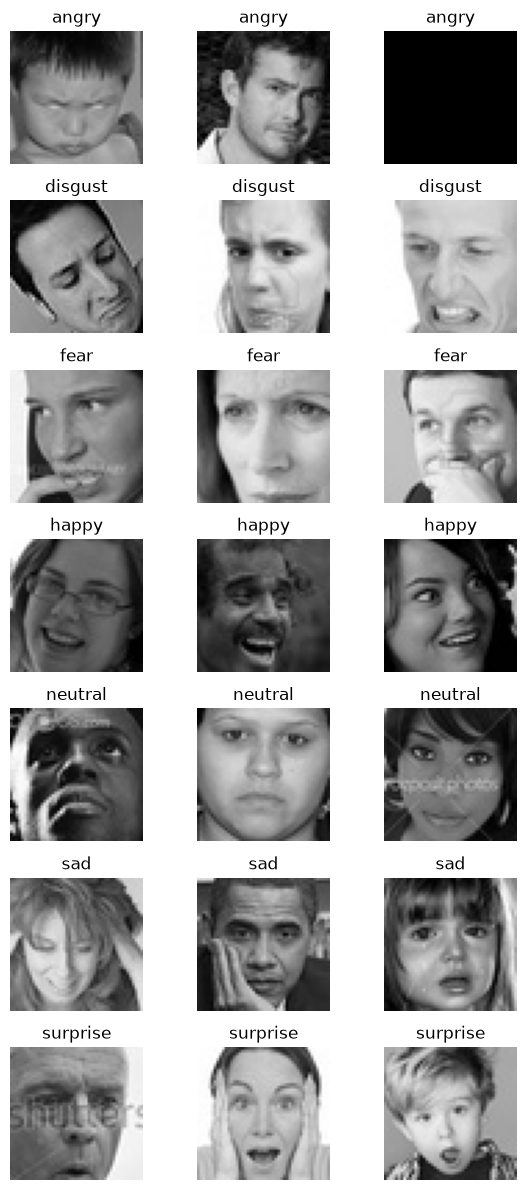

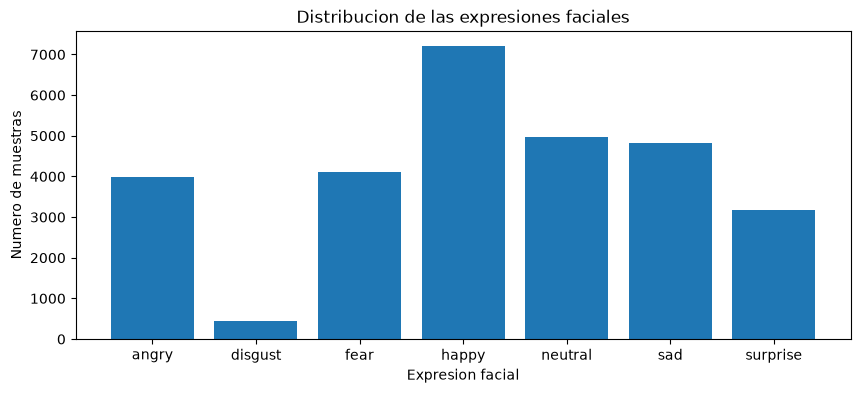

In [3]:
folder_train = "FER2013/train"
folder_test = "FER2013/test"

ext = (".jpg", ".jpeg", ".png")

print("Loading training dataset")

X_train, y_train, nperclass_train, classlabels = LoadDataset(
    folder_train, ext
)

print("Loading test dataset")

X_test, y_test, nperclass_test, classlabels_test = LoadDataset(
    folder_test, ext
)

assert classlabels == classlabels_test, "Las clases no coinciden"

# Convierte a numpy array
X_train = np.array(X_train, dtype='uint8')
y_train = np.array(y_train, dtype='int32')

X_test = np.array(X_test, dtype='uint8')
y_test = np.array(y_test, dtype='int32')

width = 48
height = 48

# Obtiene numero de muestras y caracteristicas
n_samples, n_features = X_train.shape

# Obtiene nombres de las clases
class_names = np.array(classlabels)
n_classes = class_names.shape[0]

print("\nDataset info:")
print("Training samples:", n_samples)
print("Test samples:", len(X_test))
print("Features:", n_features)
print("Classes:", n_classes)
print("Class names:", class_names)
print("Training samples per class:", nperclass_train)
print("Test samples per class:", nperclass_test)

# Muestra las primeras muestras de cada clase
nims2show = 3

fig, axes = plt.subplots(n_classes, nims2show, figsize=(6, 12))

for nc in range(n_classes):

    indices = np.where(y_train == nc)[0]

    for i in range(nims2show):

        gray = X_train[indices[i]].reshape(height, width)

        axes[nc, i].imshow(gray, cmap='gray', vmin=0, vmax=255)
        axes[nc, i].set_title(class_names[nc])
        axes[nc, i].axis('off')

plt.tight_layout()
plt.show()

# Distribucion de las clases
plt.figure(figsize=(10, 4))
plt.bar(class_names, nperclass_train)
plt.title("Distribucion de las expresiones faciales")
plt.xlabel("Expresion facial")
plt.ylabel("Numero de muestras")
plt.show()

In [4]:
# Obtiene HOG para determinada configuración de celdas

ncellsx = 4
ncellsy = 4

t0 = time()

print("Calculando HOG de entrenamiento...")

Xhog4x4_train = GetHOG(
    X_train, ncellsx, ncellsy, width, height
)

print("Calculando HOG de test...")

Xhog4x4_test = GetHOG(
    X_test, ncellsx, ncellsy, width, height
)

# Convierte a numpy array
Xhog4x4_train = np.array(Xhog4x4_train, dtype='float32')
Xhog4x4_test = np.array(Xhog4x4_test, dtype='float32')

print("Training:", Xhog4x4_train.shape)
print("Test:", Xhog4x4_test.shape)

print("Tiempo: %0.3fs" % (time() - t0))

Calculando HOG de entrenamiento...
Calculando HOG de test...
Training: (28709, 144)
Test: (7178, 144)
Tiempo: 14.649s


In [6]:
# HOG + SVM

print("\nHOG+SVM")

y_pred, y_test, modelo, scaler = GetPredictions(
    Xhog4x4_train,
    y_train,
    Xhog4x4_test,
    y_test
)

print("\nHOG Metrics")

print("Accuracy:", accuracy_score(y_test, y_pred))

print(classification_report(
    y_test,
    y_pred,
    labels=range(n_classes),
    target_names=class_names,
    zero_division=0
))


HOG+SVM
SVM Normalization
SVM training...
done in 111.160s
Predicting...
done in 28.963s

HOG Metrics
Accuracy: 0.47339091668988575
              precision    recall  f1-score   support

       angry       0.35      0.38      0.36       958
     disgust       0.53      0.62      0.57       111
        fear       0.40      0.29      0.33      1024
       happy       0.64      0.64      0.64      1774
     neutral       0.45      0.43      0.44      1233
         sad       0.36      0.39      0.38      1247
    surprise       0.53      0.63      0.57       831

    accuracy                           0.47      7178
   macro avg       0.47      0.48      0.47      7178
weighted avg       0.47      0.47      0.47      7178



Confusion matrix:
[[ 360   15   77  132  138  157   79]
 [  15   69    6    9    5    5    2]
 [ 135   14  296  103  120  217  139]
 [ 139    8   90 1136  121  182   98]
 [ 136    6   90  164  529  222   86]
 [ 193   12  131  161  201  487   62]
 [  49    7   55   76   56   67  521]]


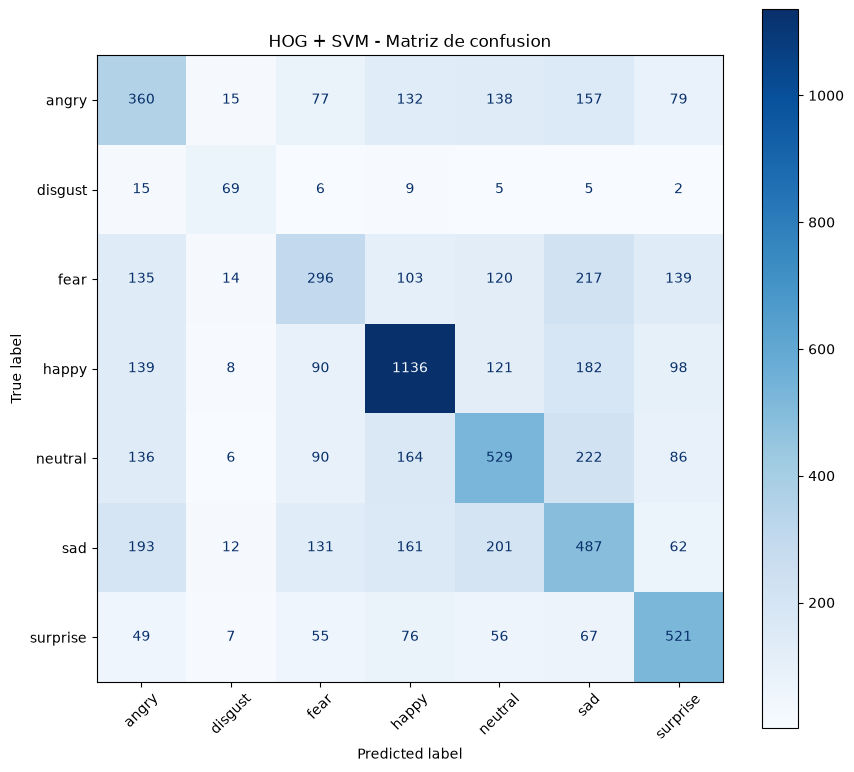

In [7]:
# Matriz de confusion

print("Confusion matrix:")

cm = confusion_matrix(
    y_test,
    y_pred,
    labels=range(n_classes)
)

print(cm)

fig, ax = plt.subplots(figsize=(9, 8))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)

disp.plot(
    ax=ax,
    cmap="Blues",
    xticks_rotation=45
)

plt.title("HOG + SVM - Matriz de confusion")

plt.tight_layout()
plt.savefig("matriz_confusion.png", dpi=150)
plt.show()

In [8]:
# Guarda el modelo entrenado y su configuracion

joblib.dump(
    {
        "modelo": modelo,
        "scaler": scaler,
        "class_names": class_names,
        "width": width,
        "height": height,
        "ncellsx": ncellsx,
        "ncellsy": ncellsy
    },
    "modelo_expresiones.pkl"
)

print("Modelo guardado correctamente")

Modelo guardado correctamente
